In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_fp = "olive_oils.csv"
response_name = "Region"
remove_predictors = ["Area"]
seed = 598

In [3]:
raw_df = pd.read_csv(data_fp)
filter_df = raw_df.drop(remove_predictors, axis=1)
X = filter_df.copy().drop(response_name, axis=1)
y = filter_df.copy()[response_name]

filter_df.head()

,Region,palmitic,palmitoleic,stearic,oleic,linoleic,linolenic,arachidic,eicosenoic
0,South,1075,75,226,7823,672,36,60,29
1,South,1088,73,224,7709,781,31,61,29
2,South,911,54,246,8113,549,31,63,29
3,South,966,57,240,7952,619,50,78,35
4,South,1051,67,259,7771,672,50,80,46


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3,
    random_state=seed,
    stratify=y
)

In [5]:
# a

lda = LinearDiscriminantAnalysis()
lda = lda.fit(X_train, y_train)

qda = QuadraticDiscriminantAnalysis()
qda = qda.fit(X_train, y_train)

lr = LogisticRegression(max_iter=2000, random_state=seed)
lr = lr.fit(X_train, y_train)

LDA                  | Train Acc: 0.9875 | Test Acc: 1.0000
QDA                  | Train Acc: 1.0000 | Test Acc: 1.0000
Logistic Regression  | Train Acc: 1.0000 | Test Acc: 1.0000


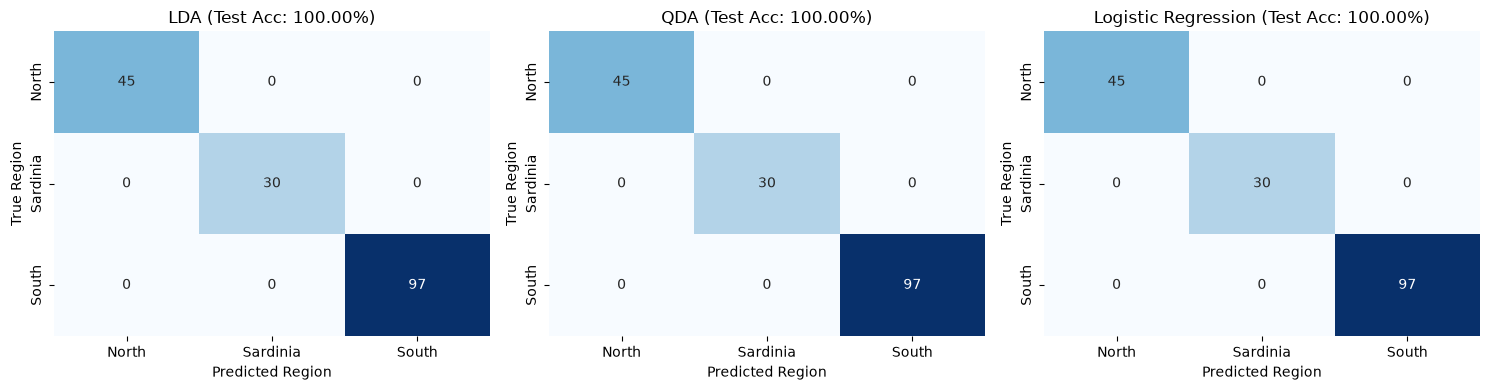

In [6]:
# b

models = {
    'LDA': {},
    'QDA': {},
    'Logistic Regression': {},
}

# Predictions
models['LDA']['preds'] = lda.predict(X_test)
models['QDA']['preds'] = qda.predict(X_test)
models['Logistic Regression']['preds'] = lr.predict(X_test)

# Accuracies
models['LDA']['train acc'] = lda.score(X_train, y_train)
models['QDA']['train acc'] = qda.score(X_train, y_train)
models['Logistic Regression']['train acc'] = lr.score(X_train, y_train)

models['LDA']['test acc'] = lda.score(X_test, y_test)
models['QDA']['test acc'] = qda.score(X_test, y_test)
models['Logistic Regression']['test acc'] = lr.score(X_test, y_test)

for name, info in models.items():
    print(f"{name:20s} | Train Acc: {info['train acc']:.4f} | Test Acc: {info['test acc']:.4f}")

labels = lda.classes_
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (name, info) in enumerate(models.items()):
    cm = confusion_matrix(y_test, info['preds'], labels=labels)
    info['cm'] = cm

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        cbar=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{name} (Test Acc: {info['test acc']:.2%})")
    axes[i].set_xlabel("Predicted Region")
    axes[i].set_ylabel("True Region")

plt.tight_layout()
plt.show()


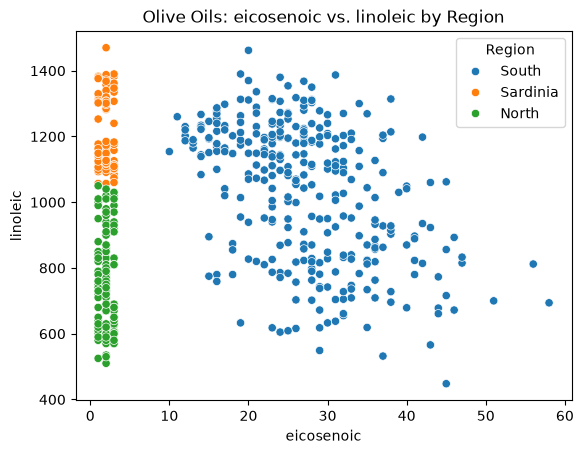

In [7]:
# c
sns.scatterplot(data=raw_df, x='eicosenoic', y='linoleic', hue='Region')
plt.title("Olive Oils: eicosenoic vs. linoleic by Region")
plt.show()

# Part C

The plot above suggests that the olive oil from the South region has a clear separation from the Sardinia and North region olive oils on the eicosenoic axis. The South region has a composition of 0.1% - 0.6% eicosenoic while the Sardinia and North regions have less than 0.05%. This differs on the linoleic axis where the Sardinia and North regions have clear separation just above 10% while the South region ranges from the North regions low of ~5% to the Sardinia regions high of ~15%.

# Part D

**Is there a model that seems to perform better overall on the test set?**

All models tied for first place with 100% test accuracy (0 test misclassifications).

**Which model misclassified more observations?**

On the test set, no model misclassified any observations. On the training set, LDA was the only model to misclassify observations (achieving 98.75% accuracy with 5 training errors), while QDA and Logistic Regression achieved 100% training accuracy.

**Which region is classified most / least accurately, and which pair of regions is most often confused?**

- Most accurately: South region is classified with 100% accuracy across all models on both training and test sets, without any confusion. This is due to its high eicosenoic levels as demonstrated in part C.
- Least accurately: Sardinia and North regions, as all training misclassifications in LDA occurred between this pair.
- Most often confused pair: North and Sardinia regions along their overlapping fatty acid profiles (e.g., linoleic and oleic).

**Does QDA improve on LDA here, or does the extra covariance structure look like overfit? Relate this to the class sizes and to part (c).**

No, QDA does not improve on LDA on the test set, as both achieve 100% test accuracy. The extra covariance structure in QDA represents unnecessary complexity and potential overfit:

- Class sizes: QDA estimates a separate $8 \times 8$ covariance matrix (36 independent parameters + 8 means) for each class. For small classes like Sardinia ($n \approx 69$ in the training set), estimating so many parameters from limited data increases estimation variance.
- Connection to Part C: As shown in part C, just two fatty acids (eicosenoic and linoleic) already produce clean, nearly linear separation among all three regions. Therefore, LDA's single pooled covariance matrix (linear decision boundaries) is already sufficient, and QDA's quadratic boundaries provide no empirical benefit.

**The Sardinia test slice is small (on the order of 30 oils). Comment on the direction of the errors, not on a one- or two-oil swing in accuracy.**

Because of the small sample size, a single misclassified oil creates an immediate ~3.4% swing in accuracy. This means small percentage differences in test accuracy reflect sample variance rather than true differences in model capability. Looking at the direction of errors:

1. No errors involve the South region.
2. North region has substantially larger sample size and training prior than Sardinia, so LDA's prior weighted decision boundary naturally favors the more populous class.